# Step 1 — Evaluation Framework

The experiments in `fake_job_detection.ipynb` used one grouped split with only 128 fake postings in validation. With that few positives, the standard error of fake-class recall is about ±0.04, so differences of a few F1 points between experiments cannot be told apart from noise.

This notebook sets up the protocol that every later experiment will use and re-measures the current final model as the **baseline**:

1. **Held-out test set unchanged.** The same 2,597 test postings (131 fake) as in the main notebook. They are not used for model selection.
2. **Repeated grouped cross-validation on the development data** (training + validation, 15,001 postings): `StratifiedGroupKFold`, 5 folds × 3 repeats, using the same description-similarity groups.
3. **Nested threshold choice.** In every outer fold, the decision threshold is chosen from out-of-fold scores inside the outer training data (3 inner grouped folds). The F1 reported on an outer fold is therefore not tuned on that fold.
4. **Metrics for the fake class:** PR-AUC (average precision) as the main threshold-free metric, ROC AUC, and F1 / precision / recall at the nested threshold. Results are reported as mean ± standard deviation over the 15 outer folds.
5. **Paired comparisons.** Every model is evaluated on identical folds, so two models can be compared fold by fold.
6. **Bootstrap confidence intervals** for test-set results, resampling whole similarity groups.

The shared code lives in the `fakejob` package next to this notebook.

In [1]:
import sklearn

if sklearn.__version__ != "1.6.1":
    raise RuntimeError(
        f"This notebook uses scikit-learn 1.6.1 (found {sklearn.__version__}). "
        "Install the pinned versions with: pip install -r requirements.txt"
    )

import warnings

# kagglehub imports tqdm.auto, which warns when ipywidgets is not installed.
warnings.filterwarnings("ignore", message="IProgress not found")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fakejob.data import load_split, reference_features
from fakejob.evaluation import bootstrap_ci, compare, model_scores, repeated_group_cv
from fakejob.models import REFERENCE_THRESHOLD, reference_pipeline

pd.set_option("display.precision", 3)
N_JOBS = -1  # outer folds run in parallel; set to 1 if memory is limited

## Data and Fixed Split

`load_split()` repeats the cleaning, grouping and 20-fold assignment from the main notebook. The assertions confirm that the split is identical.

In [2]:
split = load_split()
y = split.y

sizes = pd.DataFrame({
    "Rows": [len(split.train_index), len(split.val_index), len(split.test_index)],
    "Fake rows": [int(y.loc[idx].sum()) for idx in (split.train_index, split.val_index, split.test_index)],
}, index=["Training", "Validation", "Test"])
sizes["Fake %"] = sizes["Fake rows"] / sizes["Rows"] * 100
display(sizes)

assert len(split.model_df) == 17598
assert split.groups.nunique() == 12372
assert sizes["Rows"].tolist() == [11850, 3151, 2597]
assert sizes["Fake rows"].tolist() == [596, 128, 131]

dev_index = split.dev_index
X_dev = reference_features(split.model_df).loc[dev_index]
y_dev = y.loc[dev_index]
groups_dev = split.groups.loc[dev_index]
print(f"Development data: {len(dev_index)} postings, {int(y_dev.sum())} fake, "
      f"{groups_dev.nunique()} similarity groups")

,Rows,Fake rows,Fake %
Training,11850,596,5.030
Validation,3151,128,4.062
Test,2597,131,5.044


Development data: 15001 postings, 724 fake, 10502 similarity groups


## Baseline: Current Final Model under Repeated Grouped CV

The baseline is the class-weighted Linear SVM from Experiment 3 (TF-IDF on title, company profile and description, plus employment type, required experience, telecommuting and company logo). It is rebuilt from scratch in every fold.

Two sets of threshold metrics are reported:
- `f1`, `precision`, `recall`: at the **nested** threshold chosen inside each training fold (honest estimate).
- `*_fixed`: at the threshold stored with the saved model (−0.05), for continuity with the main notebook.

In [3]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=FutureWarning)
    baseline = repeated_group_cv(
        reference_pipeline(), X_dev, y_dev, groups_dev,
        name="Reference SVM", n_splits=5, n_repeats=3, inner_splits=3, seed=0,
        fixed_threshold=REFERENCE_THRESHOLD, n_jobs=N_JOBS,
    )

display(baseline.folds.drop(columns=["precision_fixed", "recall_fixed"]))
baseline.summary().to_frame("Mean ± std over 15 folds")

,repeat,fold,n_test,n_fake,threshold,average_precision,roc_auc,f1,precision,recall,f1_fixed
0,0,0,2671,127,-0.052,0.836,0.978,0.737,0.798,0.685,0.737
1,0,1,2912,146,-0.127,0.816,0.972,0.698,0.735,0.664,0.725
2,0,2,2995,164,-0.006,0.823,0.964,0.781,0.855,0.720,0.776
3,0,3,3240,157,-0.162,0.899,0.989,0.815,0.765,0.873,0.833
4,0,4,3183,130,-0.015,0.828,0.986,0.685,0.702,0.669,0.703
5,1,0,3318,115,-0.076,0.765,0.972,0.718,0.752,0.687,0.725
6,1,1,3198,194,-0.119,0.907,0.989,0.837,0.828,0.845,0.844
7,1,2,2810,133,-0.057,0.782,0.980,0.640,0.684,0.602,0.643
8,1,3,2725,99,-0.060,0.798,0.971,0.739,0.800,0.687,0.729
9,1,4,2950,183,-0.100,0.821,0.974,0.777,0.783,0.770,0.780


,Mean ± std over 15 folds
threshold,-0.069 ± 0.049
average_precision,0.825 ± 0.057
roc_auc,0.978 ± 0.008
f1,0.748 ± 0.069
precision,0.786 ± 0.055
recall,0.719 ± 0.100
f1_fixed,0.753 ± 0.067
precision_fixed,0.799 ± 0.052
recall_fixed,0.715 ± 0.093


### How much do scores vary between folds?

Each point is one outer fold (≈3,000 postings, ≈145 fake). The spread shows how much a single split can move the result.

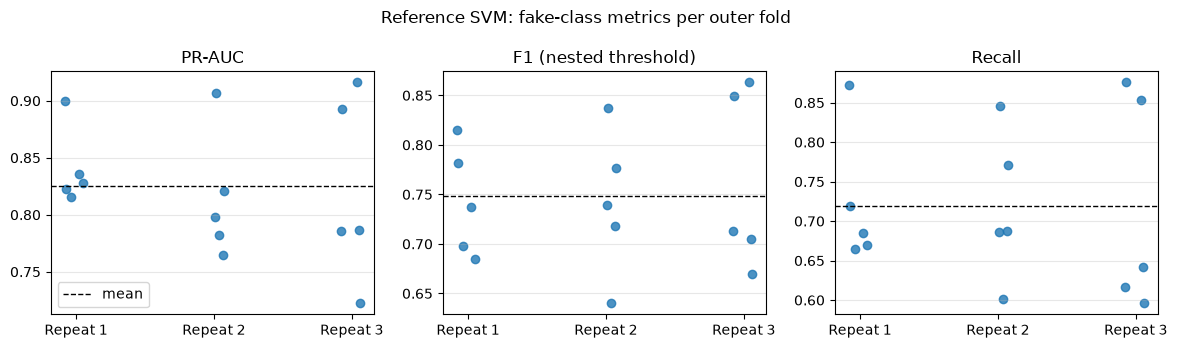

,min,max,range
average_precision,0.722,0.916,0.194
f1,0.640,0.863,0.223
precision,0.684,0.873,0.190
recall,0.596,0.876,0.280


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=False)
for ax, metric, label in zip(
    axes, ["average_precision", "f1", "recall"], ["PR-AUC", "F1 (nested threshold)", "Recall"]
):
    values = baseline.folds[metric]
    jitter = np.random.default_rng(0).uniform(-0.08, 0.08, len(values))
    ax.scatter(baseline.folds["repeat"] + jitter, values, alpha=0.8)
    ax.axhline(values.mean(), color="black", linewidth=1, linestyle="--", label="mean")
    ax.set_xticks([0, 1, 2], ["Repeat 1", "Repeat 2", "Repeat 3"])
    ax.set_title(label)
    ax.grid(axis="y", alpha=0.3)
axes[0].legend()
fig.suptitle("Reference SVM: fake-class metrics per outer fold")
fig.tight_layout()
plt.show()

spread = baseline.folds[["average_precision", "f1", "precision", "recall"]].agg(["min", "max"]).T
spread["range"] = spread["max"] - spread["min"]
spread

## Example Paired Comparison: Do the Structured Features Help?

To show how later experiments will be compared, the text-only model from Experiment 2 (same TF-IDF text, no structured features) is evaluated on **the same folds**. `compare()` reports the mean paired difference (candidate − baseline), its standard deviation, and in how many of the 15 folds the candidate was better.

A change is treated as a real improvement only if the mean difference is clearly larger than its fold-to-fold standard deviation and it improves in most folds.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC

text_only = make_pipeline(
    ColumnTransformer([("text", TfidfVectorizer(), "combined_text")]),
    LinearSVC(class_weight="balanced", random_state=42),
)

with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=FutureWarning)
    text_only_result = repeated_group_cv(
        text_only, X_dev, y_dev, groups_dev,
        name="Text-only SVM", n_splits=5, n_repeats=3, inner_splits=3, seed=0, n_jobs=N_JOBS,
    )

display(pd.concat([baseline.summary(), text_only_result.summary()], axis=1).dropna())
compare(text_only_result, baseline, metrics=["average_precision", "roc_auc", "f1", "precision", "recall"])

,Reference SVM,Text-only SVM
threshold,-0.069 ± 0.049,-0.133 ± 0.073
average_precision,0.825 ± 0.057,0.814 ± 0.056
roc_auc,0.978 ± 0.008,0.968 ± 0.013
f1,0.748 ± 0.069,0.757 ± 0.057
precision,0.786 ± 0.055,0.786 ± 0.063
recall,0.719 ± 0.100,0.737 ± 0.089


,baseline,candidate,mean_diff,std_diff,folds_improved
metric,,,,,
average_precision,0.814,0.825,1.153e-02,0.017,11/15
roc_auc,0.968,0.978,9.725e-03,0.006,15/15
f1,0.757,0.748,-8.970e-03,0.035,6/15
precision,0.786,0.786,3.380e-04,0.046,8/15
recall,0.737,0.719,-1.833e-02,0.062,5/15


In the table above, *baseline* is the text-only model and *candidate* is the reference model, so a positive `mean_diff` means the structured features helped.

## Test-Set Confidence Intervals for the Saved Model

The saved model's test result (F1 0.800) was already reported in the main notebook. Here the same predictions get 95% confidence intervals from a group-level bootstrap (2,000 resamples). No model is selected on the test set in this step.

In [6]:
import joblib

saved = joblib.load("fake_job_structured_model.joblib")
assert saved["threshold"] == REFERENCE_THRESHOLD

X_test = reference_features(split.model_df).loc[split.test_index]
y_test = y.loc[split.test_index]
test_scores = model_scores(saved["pipeline"], X_test)

test_ci = bootstrap_ci(
    y_test, test_scores, REFERENCE_THRESHOLD, split.groups.loc[split.test_index],
    n_boot=2000, seed=0,
)
test_ci

,estimate,ci_low,ci_high
average_precision,0.866,0.773,0.927
roc_auc,0.973,0.952,0.987
f1,0.800,0.701,0.869
precision,0.860,0.760,0.930
recall,0.748,0.620,0.846


## Saved Baseline Results

Fold-level results are written to `results/` so later notebooks can compare against the baseline on identical folds without retraining it.

In [7]:
from pathlib import Path

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)
baseline.folds.to_csv(results_dir / "step1_reference_svm_folds.csv", index=False)
text_only_result.folds.to_csv(results_dir / "step1_text_only_svm_folds.csv", index=False)
test_ci.to_csv(results_dir / "step1_reference_svm_test_ci.csv")
print(sorted(p.name for p in results_dir.iterdir()))

['step1_reference_svm_folds.csv', 'step1_reference_svm_test_ci.csv', 'step1_text_only_svm_folds.csv']


## Findings

**1. Baseline for all later steps.** Under 5 × 3 repeated grouped CV with a nested threshold, the reference SVM reaches a fake-class PR-AUC of **0.825 ± 0.057** and F1 of **0.748 ± 0.069** (precision 0.786 ± 0.055, recall 0.719 ± 0.100). Using the stored threshold of −0.05 instead gives almost the same F1 (0.753), so the threshold itself transfers reasonably well.

**2. A single split is unreliable.** Across the 15 outer folds, F1 ranged from 0.640 to 0.863 and recall from 0.596 to 0.876. The F1 of 0.800 reported on both the earlier validation and test sets lies inside this range but above the CV mean, so those two splits were somewhat favourable.

**3. Test-set uncertainty.** The saved model's test F1 of 0.800 has a 95% bootstrap interval of **0.701–0.869** (recall 0.748, interval 0.620–0.846). Two models whose test F1 differs by less than about 0.08 cannot be told apart on this test set, which is why selection must happen on development CV.

**4. Earlier conclusions revisited.** The structured features (employment type, experience, telecommuting, logo) improve ranking consistently: ROC AUC +0.010 in 15/15 folds and PR-AUC +0.012 in 11/15 folds. At the chosen threshold, however, the F1 difference is −0.009 ± 0.035 (better in only 6/15 folds), i.e. not measurable. The earlier single-split claim that Experiment 3 beat Experiment 2 on F1 (0.800 vs 0.791) is therefore not supported, while the gain in PR-AUC is.

**Decision rule for Steps 2–4.** Every candidate is compared with the baseline on identical folds (`compare()`). PR-AUC is the primary metric because it does not depend on a threshold. A change is adopted when its mean paired PR-AUC gain is positive and it improves in at least **12 of 15 folds** (one-sided sign test, p ≈ 0.018). F1, precision and recall at the nested threshold are reported alongside. The test set is used once, for the final model in Step 5.